# 06 — Gender-specific preference segmentation

## Business question
**Within each gender, are there distinct groups of participants who prioritize different traits in a partner, and do those groups differ in their observed yes and mutual-match rates?**

This is a marketing analytics **segmentation and targeting** analysis. The segments are defined by participants’ stated pre-event importance weights for attractiveness, sincerity, intelligence, fun, ambition, and shared interests. Their observed decisions and matches are kept out of the clustering and used only as descriptive follow-up outcomes.

> **Important distinction:** these are segments of what participants said they value before the event. They are not segments based on what actually drove each individual choice. The outcome comparison is a separate follow-up.

## 1. Data and measurement

The source file has one row per date, so each participant appears repeatedly. We reduce it to **one row per participant** before clustering. The six preference fields are `attr1_1`, `sinc1_1`, `intel1_1`, `fun1_1`, `amb1_1`, and `shar1_1`. The cleaned unscaled file expresses these as relative weights that sum to 100; we normalize again to protect against rounding differences.

We fit segments separately for women (`gender = 0`) and men (`gender = 1`). The outcomes `dec` and `match` are not used to create segments.

In [1]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# If you run this notebook from another folder, update this path.
candidates = [Path("Speed Dating cleaned unscaled.csv"), Path("upload/Speed Dating cleaned unscaled.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place 'Speed Dating cleaned unscaled.csv' beside this notebook or update DATA_PATH.")
data = pd.read_csv(DATA_PATH)
ATTRS = ["attr1_1", "sinc1_1", "intel1_1", "fun1_1", "amb1_1", "shar1_1"]
TRAITS = ["Attractiveness", "Sincerity", "Intelligence", "Fun", "Ambition", "Shared interests"]
ATTR_TO_TRAIT = dict(zip(ATTRS, TRAITS))
GENDER_LABEL = {0: "Women", 1: "Men"}

# The six preference answers are participant-level; keep one record per iid.
person_pref = data.groupby("iid").agg(
    gender=("gender", "first"), wave=("wave", "first"),
    **{col: (col, "first") for col in ATTRS},
)
person_outcomes = data.groupby("iid").agg(
    n_dates=("dec", "count"), yes_rate=("dec", "mean"), mutual_match_rate=("match", "mean"),
)
person = person_pref.join(person_outcomes)
complete = person.dropna(subset=ATTRS).copy()
complete[ATTRS] = complete[ATTRS].div(complete[ATTRS].sum(axis=1), axis=0) * 100
sample_table = pd.DataFrame([
    {"Gender": GENDER_LABEL[g],
     "Participants with complete preferences": int((complete.gender == g).sum()),
     "Participants excluded for missing preference field": int(((person.gender == g) & person[ATTRS].isna().any(axis=1)).sum())}
    for g in [0, 1]
])
print(f"Date-level rows: {len(data):,}; unique participants: {data.iid.nunique():,}")
print("Gender coding: 0 = Women, 1 = Men")
display(sample_table)
print("Maximum within-person distinct values in any preference field:",
      int(data.groupby("iid")[ATTRS].nunique().max().max()))

Gender,Complete preference profiles,Excluded for missing preferences
Women,268,6
Men,273,4


Date-level rows: 8,378; participants: 551; complete preference profiles: 541


## 2. Select the number of segments

The six preferences are **compositional** shares of a fixed 100 points. We convert each share to a proportion and apply a square-root (Hellinger) transformation before k-means clustering. We compare **k = 2 to 5** separately for women and men using silhouette scores. Higher values indicate clearer separation. Segment names are assigned after clustering from the resulting profiles.

In [1]:
K_RANGE = range(2, 6)
SEED = 42
k_rows = []
segment_models = {}
for gender_code, gender_name in GENDER_LABEL.items():
    g = complete.loc[complete.gender.eq(gender_code)].copy()
    X = np.sqrt(g[ATTRS].to_numpy() / 100.0)  # Hellinger transform of shares
    scores = {}
    for k in K_RANGE:
        labels = KMeans(n_clusters=k, random_state=SEED, n_init=100).fit_predict(X)
        scores[k] = silhouette_score(X, labels)
        sizes = pd.Series(labels).value_counts().sort_index()
        k_rows.append({"Gender": gender_name, "k": k, "Silhouette": scores[k],
                       "Smallest segment n": int(sizes.min()),
                       "Segment sizes": ", ".join(str(int(v)) for v in sizes.values)})
    chosen_k = max(scores, key=scores.get)
    labels = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=100).fit_predict(X)
    g["cluster_id"] = labels
    means = g.groupby("cluster_id")[ATTRS].mean()
    attraction_cluster = means["attr1_1"].idxmax()
    name_map = {attraction_cluster: "Attractiveness-led",
                next(c for c in means.index if c != attraction_cluster): "Broader preference mix"}
    g["segment"] = g.cluster_id.map(name_map)
    complete.loc[g.index, "cluster_id"] = g.cluster_id
    complete.loc[g.index, "segment"] = g.segment

    # Refit with 10 initial seeds to check whether the partition is stable.
    starts = [KMeans(n_clusters=chosen_k, random_state=s, n_init=20).fit_predict(X) for s in range(10)]
    ari = [adjusted_rand_score(a, b) for a, b in itertools.combinations(starts, 2)]
    segment_models[gender_name] = {"k": chosen_k, "scores": scores, "means": means,
        "stability_min_ari": float(np.min(ari)), "stability_median_ari": float(np.median(ari))}

k_table = pd.DataFrame(k_rows)
stability_df = pd.DataFrame([
    {"Gender": gender, "Selected k": values["k"],
     "Minimum pairwise ARI across 10 starts": values["stability_min_ari"],
     "Median pairwise ARI": values["stability_median_ari"]}
    for gender, values in segment_models.items()
])
display(k_table.round({"Silhouette": 3}))
display(stability_df.round(3))

Gender,k,Silhouette,Smallest segment n,Segment sizes
Women,2,0.418,50,"218, 50"
Women,3,0.339,34,"196, 38, 34"
Women,4,0.306,14,"47, 177, 14, 30"
Women,5,0.306,13,"29, 170, 26, 13, 30"
Men,2,0.384,72,"72, 201"
Men,3,0.287,27,"158, 88, 27"
Men,4,0.269,21,"74, 150, 21, 28"
Men,5,0.223,21,"26, 21, 30, 71, 125"


Gender,Selected k,Minimum pairwise ARI across 10 starts,Median pairwise ARI
Women,2,1.0,1.0
Men,2,1.0,1.0


## 3. Segment profiles and observed outcomes

The next table reports each segment’s average preference weights, size, yes rate, and mutual-match rate. The outcomes are descriptive external checks, not inputs to clustering. Confidence intervals resample participants within each segment.

In [1]:
# Participant-bootstrap summaries; each resample draws participants, not date rows.
rng = np.random.default_rng(2026)
B = 5000
summary_rows = []
for gender_name in ["Women", "Men"]:
    gender_code = {v: k for k, v in GENDER_LABEL.items()}[gender_name]
    g = complete.loc[complete.gender.eq(gender_code)]
    for segment_name in ["Attractiveness-led", "Broader preference mix"]:
        s = g.loc[g.segment.eq(segment_name)]
        vals = s.mutual_match_rate.to_numpy(dtype=float)
        boots = np.array([rng.choice(vals, size=len(vals), replace=True).mean() for _ in range(B)])
        row = {"Gender": gender_name, "Segment": segment_name, "n": len(s),
               "Share of gender sample (%)": 100 * len(s) / len(g),
               "Average dates per person": s.n_dates.mean(),
               "Average yes rate (%)": 100 * s.yes_rate.mean(),
               "Mutual-match rate (%)": 100 * s.mutual_match_rate.mean(),
               "Match-rate CI low (%)": 100 * np.percentile(boots, 2.5),
               "Match-rate CI high (%)": 100 * np.percentile(boots, 97.5)}
        row.update({f"{ATTR_TO_TRAIT[a]} preference (%)": s[a].mean() for a in ATTRS})
        summary_rows.append(row)
segment_summary = pd.DataFrame(summary_rows)

# Difference is attraction-led minus broader mix, bootstrapped by participant within segment.
diff_rows = []
for gender_name in ["Women", "Men"]:
    gender_code = {v: k for k, v in GENDER_LABEL.items()}[gender_name]
    g = complete.loc[complete.gender.eq(gender_code)]
    a = g.loc[g.segment.eq("Attractiveness-led"), "mutual_match_rate"].to_numpy(dtype=float)
    b = g.loc[g.segment.eq("Broader preference mix"), "mutual_match_rate"].to_numpy(dtype=float)
    boot_diff = np.array([rng.choice(a, size=len(a), replace=True).mean() -
                          rng.choice(b, size=len(b), replace=True).mean() for _ in range(B)])
    diff_rows.append({"Gender": gender_name,
                      "Difference: attraction-led minus broader (pp)": 100 * (a.mean() - b.mean()),
                      "95% CI low (pp)": 100 * np.percentile(boot_diff, 2.5),
                      "95% CI high (pp)": 100 * np.percentile(boot_diff, 97.5)})
match_difference = pd.DataFrame(diff_rows)

summary_display = segment_summary[["Gender", "Segment", "n", "Share of gender sample (%)",
    "Average dates per person", "Average yes rate (%)", "Mutual-match rate (%)",
    "Match-rate CI low (%)", "Match-rate CI high (%)"] +
    [f"{ATTR_TO_TRAIT[a]} preference (%)" for a in ATTRS]].round(1)
profile_table = segment_summary[["Gender", "Segment", "n", "Share of gender sample (%)"] +
    [f"{ATTR_TO_TRAIT[a]} preference (%)" for a in ATTRS]].copy()
profile_table["Top two traits"] = profile_table[[f"{ATTR_TO_TRAIT[a]} preference (%)" for a in ATTRS]].apply(
    lambda row: ", ".join(row.sort_values(ascending=False).index[:2].str.replace(" preference (%)", "", regex=False)), axis=1)
profile_table = profile_table.round(1)
display(summary_display)
display(match_difference.round(1))
display(profile_table)

Gender,Segment,n,Share of gender sample (%),Average dates per person,Average yes rate (%),Mutual-match rate (%),Match-rate CI low (%),Match-rate CI high (%),Attractiveness preference (%),Sincerity preference (%),Intelligence preference (%),Fun preference (%),Ambition preference (%),Shared interests preference (%)
Women,Attractiveness-led,50,18.7,15.4,35.6,18.9,14.7,23.2,31.6,13.3,22.9,17.6,9.2,5.5
Women,Broader preference mix,218,81.3,15.3,38.2,16.5,14.6,18.4,14.8,19.4,20.5,17.3,13.7,14.4
Men,Attractiveness-led,72,26.4,15.1,45.1,18.6,14.6,22.8,42.6,13.6,17.4,18.6,3.5,4.2
Men,Broader preference mix,201,73.6,15.2,49.3,16.1,14.2,18.1,21.4,17.3,20.1,17.2,10.6,13.3


Gender,Match-rate difference: attraction-led minus broader (pp),95% CI low (pp),95% CI high (pp)
Women,2.4,-2.5,7.2
Men,2.5,-1.8,7.1


Gender,Segment,n,Share of gender sample (%),Attractiveness preference (%),Sincerity preference (%),Intelligence preference (%),Fun preference (%),Ambition preference (%),Shared interests preference (%),Top two traits
Women,Attractiveness-led,50,18.7,31.6,13.3,22.9,17.6,9.2,5.5,"Attractiveness, Intelligence"
Women,Broader preference mix,218,81.3,14.8,19.4,20.5,17.3,13.7,14.4,"Intelligence, Sincerity"
Men,Attractiveness-led,72,26.4,42.6,13.6,17.4,18.6,3.5,4.2,"Attractiveness, Fun"
Men,Broader preference mix,201,73.6,21.4,17.3,20.1,17.2,10.6,13.3,"Attractiveness, Intelligence"


## 4. Visuals

The heatmap is the primary segment exhibit. The PCA map compresses the six transformed preference dimensions to two axes for display only; clustering was estimated in all six dimensions.

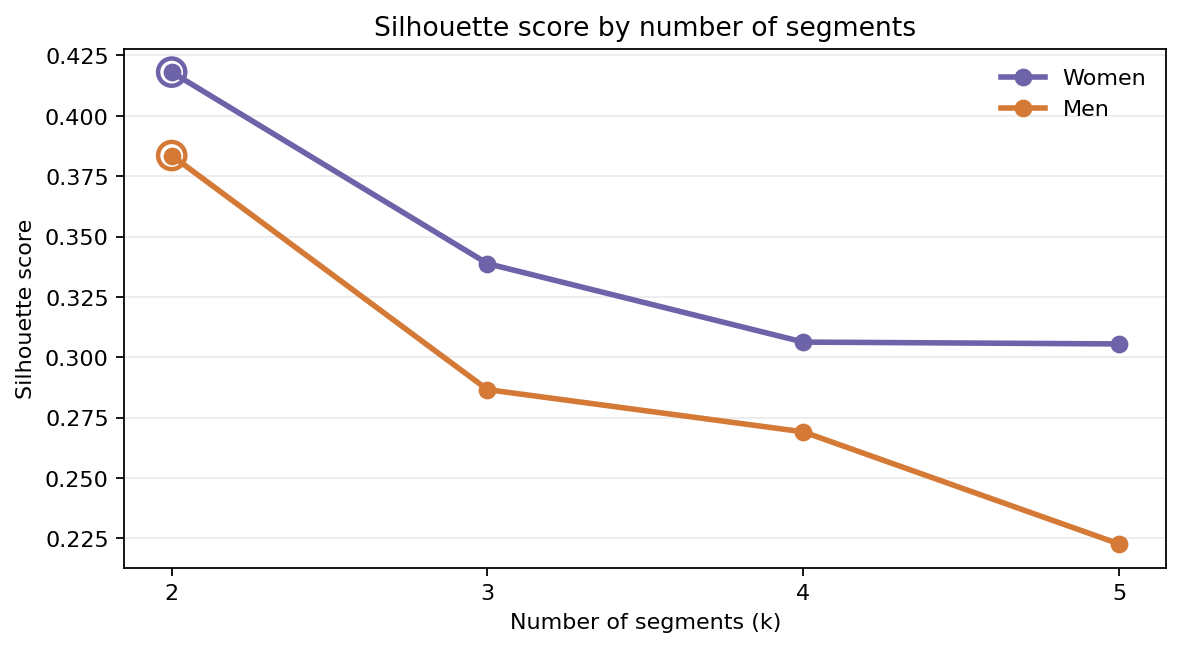

In [1]:
# Silhouette score by k; open-circle markers identify the selected k.
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for gender_name, color in [("Women", "#6C63A8"), ("Men", "#D47A36")]:
    t = k_table.loc[k_table.Gender.eq(gender_name)]
    ax.plot(t.k, t.Silhouette, marker="o", linewidth=2.5, markersize=7, label=gender_name, color=color)
    chosen = segment_models[gender_name]["k"]
    score = t.loc[t.k.eq(chosen), "Silhouette"].iloc[0]
    ax.scatter([chosen], [score], s=150, facecolors="none", edgecolors=color, linewidths=2)
ax.set(title="Silhouette score by number of segments", xlabel="Number of segments (k)", ylabel="Silhouette score")
ax.set_xticks(list(K_RANGE)); ax.grid(axis="y", alpha=.25); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

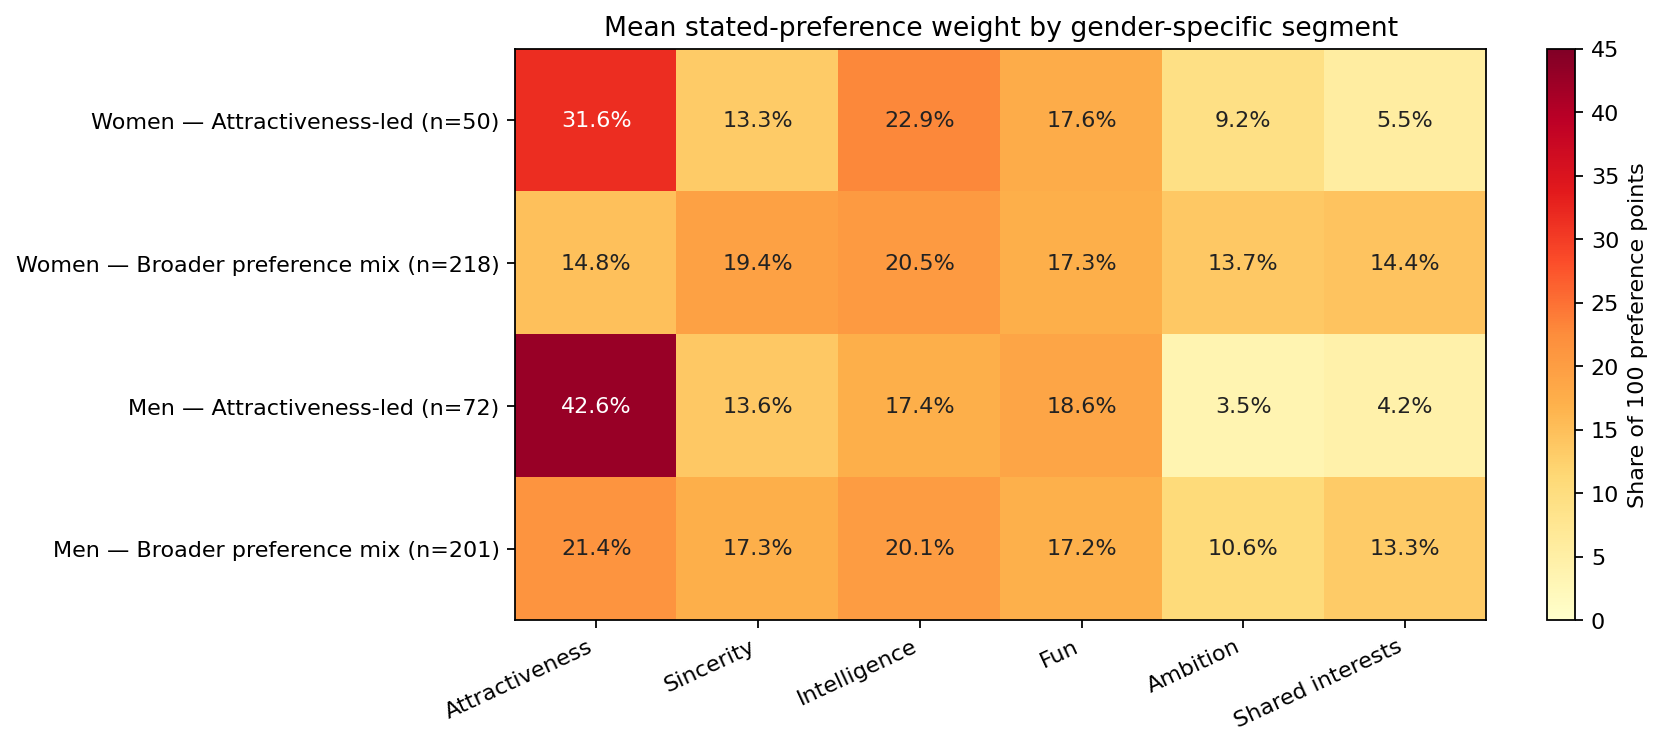

In [1]:
# Average stated-preference profiles by gender-specific segment.
rows, row_labels = [], []
for gender_name, gender_code in [("Women", 0), ("Men", 1)]:
    for segment_name in ["Attractiveness-led", "Broader preference mix"]:
        s = complete.loc[complete.gender.eq(gender_code) & complete.segment.eq(segment_name)]
        rows.append(s[ATTRS].mean().to_numpy())
        row_labels.append(f"{gender_name} — {segment_name} (n={len(s)})")
mat = np.vstack(rows)
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(mat, cmap="YlOrRd", aspect="auto", vmin=0, vmax=45)
ax.set_xticks(range(len(TRAITS)), TRAITS, rotation=25, ha="right")
ax.set_yticks(range(len(row_labels)), row_labels)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat[i,j]:.1f}%", ha="center", va="center",
                color="white" if mat[i,j] > 28 else "#222222", fontsize=10)
ax.set_title("Mean stated-preference weight by gender-specific segment")
fig.colorbar(im, ax=ax, label="Share of 100 preference points")
plt.tight_layout(); plt.show()

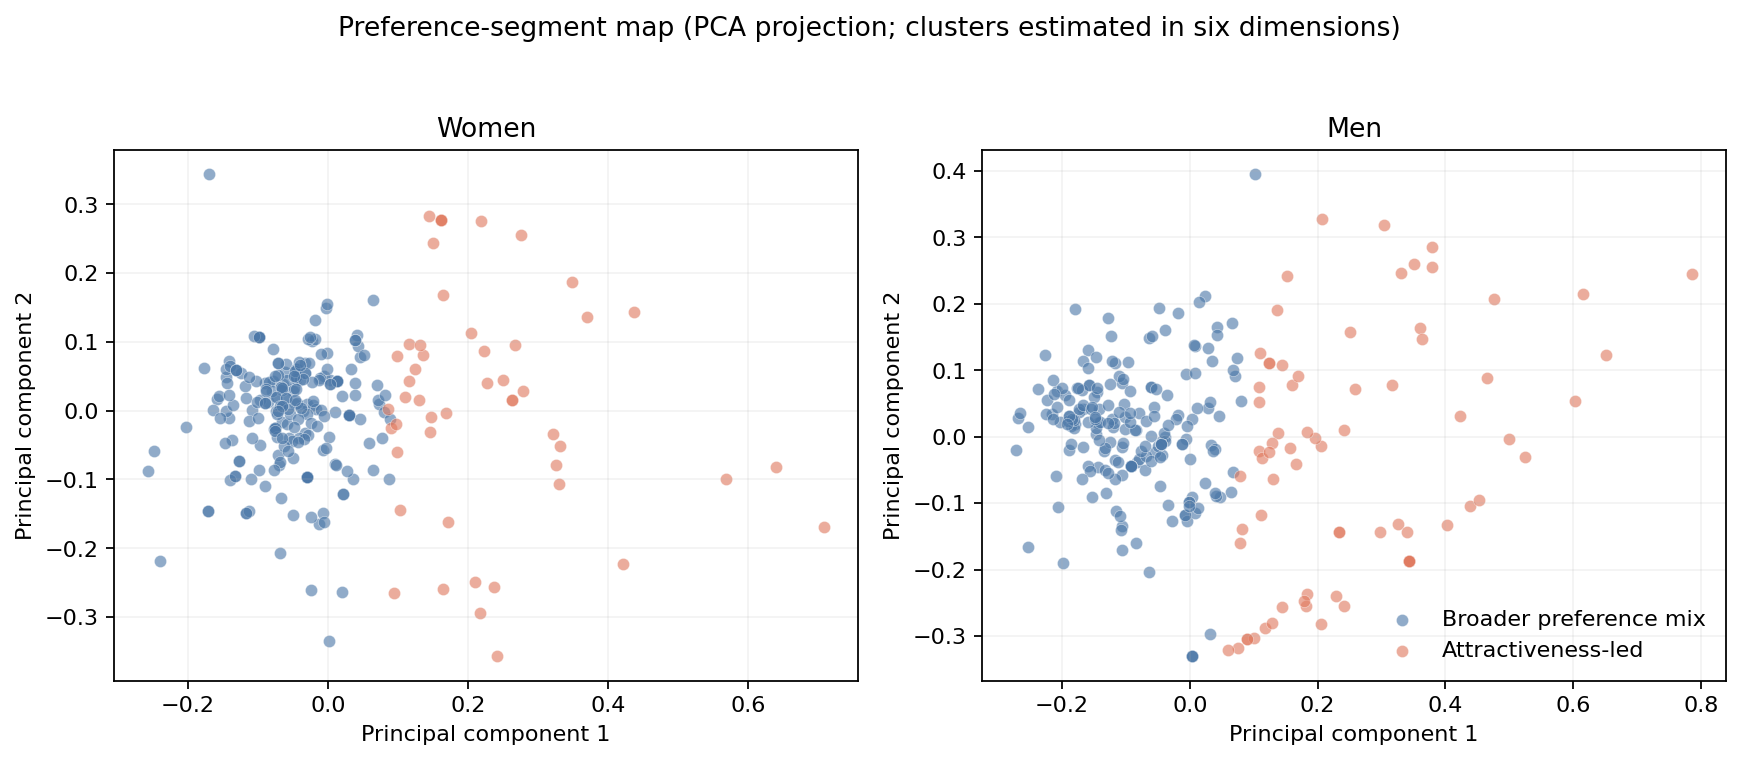

In [1]:
# PCA view is for display only; segment labels were estimated from all six traits.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
colors = {"Attractiveness-led": "#E07A5F", "Broader preference mix": "#4C78A8"}
for ax, (gender_name, gender_code) in zip(axes, [("Women", 0), ("Men", 1)]):
    g = complete.loc[complete.gender.eq(gender_code)].copy()
    X = np.sqrt(g[ATTRS].to_numpy() / 100.0)
    coords = PCA(n_components=2, random_state=SEED).fit_transform(X)
    for segment_name in ["Broader preference mix", "Attractiveness-led"]:
        mask = g.segment.eq(segment_name).to_numpy()
        ax.scatter(coords[mask, 0], coords[mask, 1], s=30, alpha=.62, label=segment_name,
                   color=colors[segment_name], edgecolor="white", linewidth=.25)
    ax.set_title(gender_name); ax.set_xlabel("Principal component 1"); ax.set_ylabel("Principal component 2"); ax.grid(alpha=.15)
axes[1].legend(frameon=False, loc="best")
fig.suptitle("Preference-segment map (PCA projection; clusters estimated in six dimensions)", y=1.03)
plt.tight_layout(); plt.show()

Gender,Men,Women
,45.7,15.7
,13.3,25.9
,23.1,32.0
,11.2,15.1
,2.0,6.0
,4.7,5.2


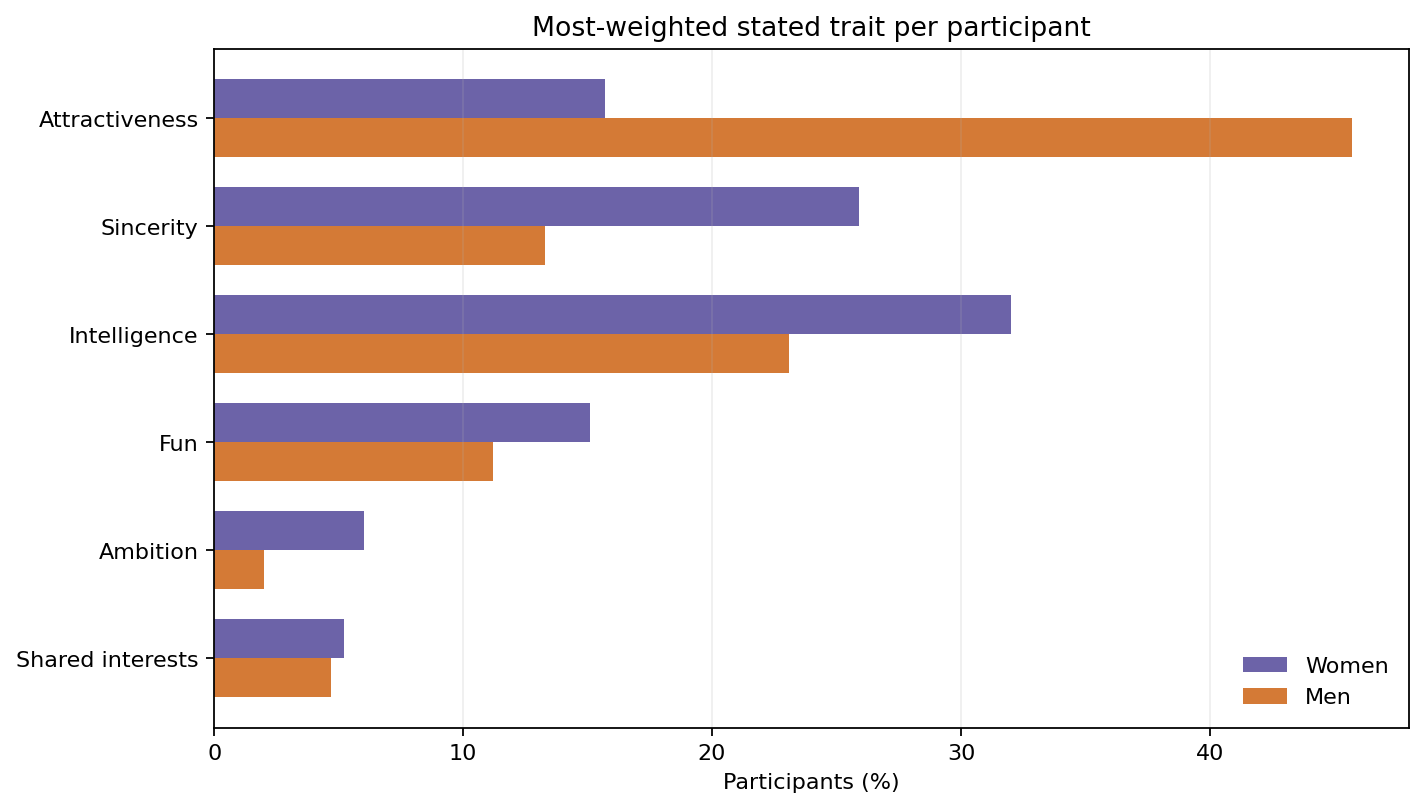

In [1]:
# Share whose single highest stated preference is each trait. Exact ties are split evenly.
top_rows = []
for gender_name, gender_code in [("Women", 0), ("Men", 1)]:
    g = complete.loc[complete.gender.eq(gender_code)]
    vals = g[ATTRS].to_numpy()
    maxima = vals.max(axis=1, keepdims=True)
    is_top = np.isclose(vals, maxima)
    fractional = is_top / is_top.sum(axis=1, keepdims=True)
    for j, trait in enumerate(TRAITS):
        top_rows.append({"Gender": gender_name, "Trait": trait,
                         "Participants equivalent": fractional[:, j].sum(),
                         "Share of gender sample (%)": 100 * fractional[:, j].mean()})
top_trait_table = pd.DataFrame(top_rows)
top_table = top_trait_table.pivot(index="Trait", columns="Gender", values="Share of gender sample (%)").reindex(TRAITS)
display(top_table.round(1))

fig, ax = plt.subplots(figsize=(9, 5.2)); y = np.arange(len(TRAITS)); height = .36
ax.barh(y-height/2, top_table["Women"], height, label="Women", color="#6C63A8")
ax.barh(y+height/2, top_table["Men"], height, label="Men", color="#D47A36")
ax.set_yticks(y, TRAITS); ax.invert_yaxis(); ax.set_xlabel("Participants (%)")
ax.set_title("Most-weighted stated trait per participant"); ax.grid(axis="x", alpha=.2); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

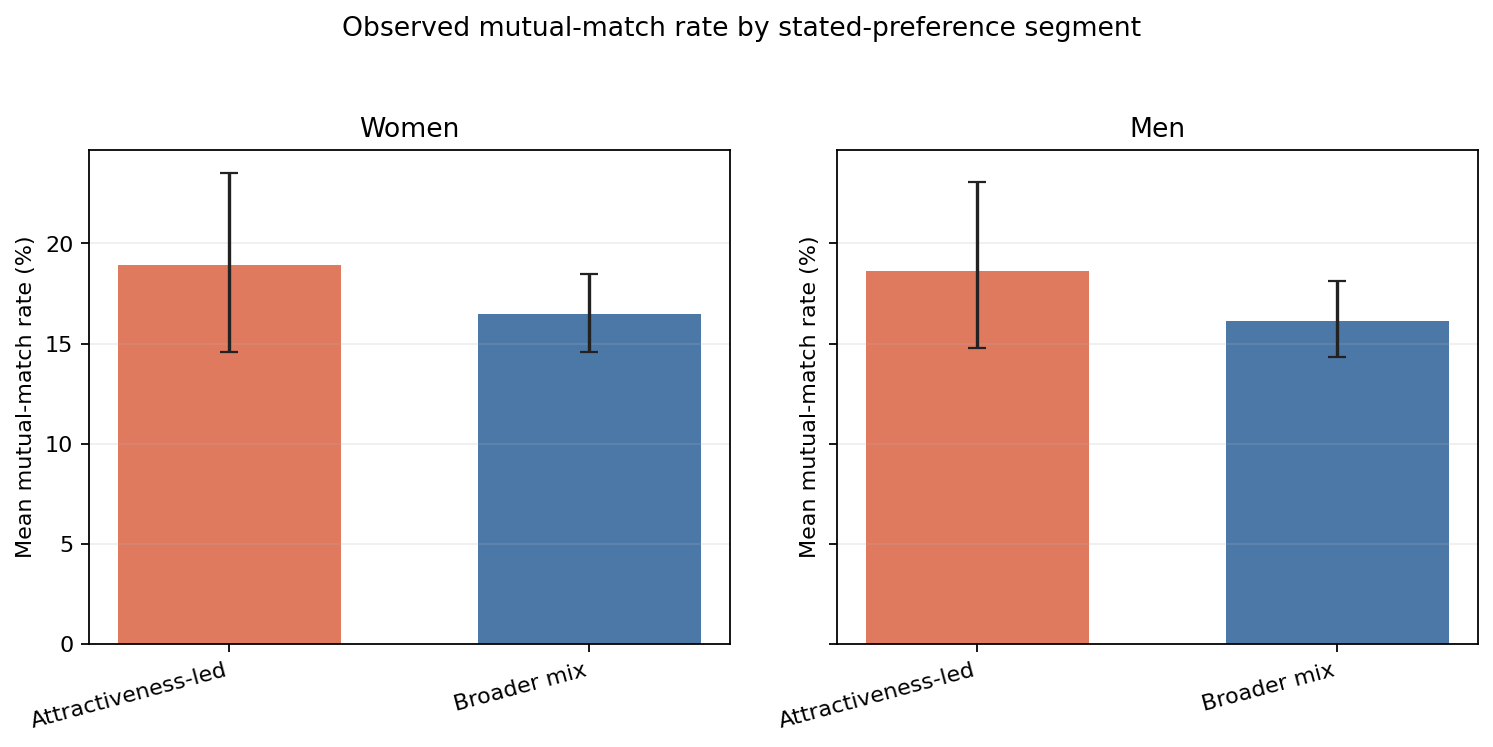

In [1]:
# Mean mutual-match rates with participant-bootstrap 95% intervals.
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.5), sharey=True)
for ax, (gender_name, gender_code) in zip(axes, [("Women", 0), ("Men", 1)]):
    g = complete.loc[complete.gender.eq(gender_code)]
    names = ["Attractiveness-led", "Broader preference mix"]
    means, lows, highs = [], [], []
    for segment_name in names:
        vals = g.loc[g.segment.eq(segment_name), "mutual_match_rate"].to_numpy(dtype=float)
        boots = np.array([rng.choice(vals, size=len(vals), replace=True).mean() for _ in range(B)])
        means.append(100 * vals.mean()); lows.append(100 * np.percentile(boots, 2.5)); highs.append(100 * np.percentile(boots, 97.5))
    x = np.arange(2)
    ax.bar(x, means, color=[colors[n] for n in names], width=.62)
    ax.errorbar(x, means, yerr=[np.array(means)-np.array(lows), np.array(highs)-np.array(means)],
                fmt="none", ecolor="#222222", capsize=4, linewidth=1.5)
    ax.set_xticks(x, ["Attractiveness-led", "Broader mix"], rotation=15, ha="right")
    ax.set_title(gender_name); ax.set_ylabel("Mean mutual-match rate (%)"); ax.grid(axis="y", alpha=.2)
fig.suptitle("Observed mutual-match rate by stated-preference segment", y=1.03)
plt.tight_layout(); plt.show()

## 5. Interpretation

- **Attractiveness-led** participants give attractiveness a substantially larger share of their preference points than the other segment.
- **Broader preference mix** participants spread their stated importance across several traits. It is not one uniform “non-attractiveness” type.
- The top-trait chart is a complementary, simpler summary of each person’s single highest-weighted trait; it is not the same as the full-profile clustering.
- The mutual-match comparison checks whether preference segments also differ in observed matches. If the bootstrap interval for the difference includes zero, describe the rates as similar in this sample; do not claim one preference causes more matches.

### Marketing implication
A dating product could ask users to allocate importance across traits and personalize ranking from the **individual’s** preference profile. These results do not support assigning preferences to users based on gender. The dataset has no subscription price, spend, retention, or lifetime data, so this analysis does not estimate pricing or customer lifetime value.

### Limitations
Segments describe stated priorities, not latent psychological types or causal choice drivers. The sample is a specific Columbia speed-dating population from 2002–2004. Gender-specific clusters are fitted separately and do not themselves constitute a formal test of gender differences. Match rates are descriptive and reflect the event design and the number and composition of dates each participant had.